<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_4_Tree_Based_Methods/Projects/Instructions/Project.4-Spotify/Spotify_Pass_09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Data Collection/Sources


### Load Modules

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier

import xgboost as xgb
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import mean_squared_error
from sklearn.metrics import accuracy_score

import requests

from google.colab import userdata
import os

### Authenticate to Hugging Face


In [15]:
# Retrieve the token from Colab's secret manager
os.environ["HF_TOKEN"] = userdata.get('hf_token')
_ = os.environ["HF_TOKEN"]
f"{_[:5]} ... {_[-3:]}"

'hf_as ... mJe'

In [16]:
os.environ["HF_ACCOUNT"] = userdata.get('hf_account')
hf_account = os.environ["HF_ACCOUNT"]
hf_account


'ericbdf7'

In [17]:
hf_repo = "Data_Science-22"
os.environ["HF_REPO"] = hf_repo
hf_repo


'Data_Science-22'

In [18]:
# Log in automatically without an interactive prompt
! hf auth login --token $HF_TOKEN


The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `hf`CLI if you want to set the git credential as well.
Token is valid (permission: fineGrained).
The token `colab` has been saved to /root/.cache/huggingface/stored_tokens
Your token has been saved to /root/.cache/huggingface/token
Login successful.
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


### Read parquet from Hugging Face


In [19]:
# Construct the base Hugging Face URL for your dataset files
hf_url = f"https://huggingface.co/datasets/{hf_account}/{hf_repo}/resolve/main/spotify.parquet"
hf_url


'https://huggingface.co/datasets/ericbdf7/Data_Science-22/resolve/main/spotify.parquet'

In [20]:
df3 = pd.read_parquet( hf_url )
df3.shape


(1556, 20)

In [21]:
df3.iloc[:,:5].info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1556 entries, 0 to 1555
Data columns (total 5 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Popularity                 1556 non-null   object
 1   Highest Charting Position  1556 non-null   int64 
 2   Number of Times Charted    1556 non-null   int64 
 3   Week of Highest Charting   1556 non-null   object
 4   Streams                    1556 non-null   object
dtypes: int64(2), object(3)
memory usage: 60.9+ KB


In [22]:
X_features = df3.drop(columns=['Popularity']).copy()
X_features

,Highest Charting Position,Number of Times Charted,Week of Highest Charting,Streams,Artist,Artist Followers,Genre,Release Date,Weeks Charted,Danceability,Energy,Loudness,Speechiness,Acousticness,Liveness,Tempo,Duration (ms),Valence,Chord
0,1,8,2021-07-23--2021-07-30,"48,633,449",Måneskin,3377762,"['indie rock italiano', 'italian pop']",2017-12-08,2021-07-23--2021-07-30\n2021-07-16--2021-07-23...,0.714,0.8,-4.808,0.0504,0.127,0.359,134.002,211560,0.589,B
1,2,3,2021-07-23--2021-07-30,"47,248,719",The Kid LAROI,2230022,['australian hip hop'],2021-07-09,2021-07-23--2021-07-30\n2021-07-16--2021-07-23...,0.591,0.764,-5.484,0.0483,0.0383,0.103,169.928,141806,0.478,C#/Db
2,1,11,2021-06-25--2021-07-02,"40,162,559",Olivia Rodrigo,6266514,['pop'],2021-05-21,2021-07-23--2021-07-30\n2021-07-16--2021-07-23...,0.563,0.664,-5.044,0.154,0.335,0.0849,166.928,178147,0.688,A
3,3,5,2021-07-02--2021-07-09,"37,799,456",Ed Sheeran,83293380,"['pop', 'uk pop']",2021-06-25,2021-07-23--2021-07-30\n2021-07-16--2021-07-23...,0.808,0.897,-3.712,0.0348,0.0469,0.364,126.026,231041,0.591,B
4,5,1,2021-07-23--2021-07-30,"33,948,454",Lil Nas X,5473565,"['lgbtq+ hip hop', 'pop rap']",2021-07-23,2021-07-23--2021-07-30,0.736,0.704,-7.409,0.0615,0.0203,0.0501,149.995,212000,0.894,D#/Eb
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1551,195,1,2019-12-27--2020-01-03,"4,630,675",Dua Lipa,27167675,"['dance pop', 'pop', 'uk pop']",2017-06-02,2019-12-27--2020-01-03,0.762,0.7,-6.021,0.0694,0.00261,0.153,116.073,209320,0.608,A
1552,196,1,2019-12-27--2020-01-03,"4,623,030",Jorge & Mateus,15019109,"['sertanejo', 'sertanejo universitario']",2019-10-11,2019-12-27--2020-01-03,0.528,0.87,-3.123,0.0851,0.24,0.333,152.37,181930,0.714,B
1553,197,1,2019-12-27--2020-01-03,"4,620,876",Camila Cabello,22698747,"['dance pop', 'electropop', 'pop', 'post-teen ...",2018-01-12,2019-12-27--2020-01-03,0.765,0.523,-4.333,0.03,0.184,0.132,104.988,217307,0.394,D
1554,198,1,2019-12-27--2020-01-03,"4,607,385","Dadá Boladão, Tati Zaqui, OIK",208630,"['brega funk', 'funk carioca']",2019-09-25,2019-12-27--2020-01-03,0.832,0.55,-7.026,0.0587,0.249,0.182,154.064,152784,0.881,F


In [23]:
y_target = df3['Popularity'].copy()
y_target

,Popularity
0,100
1,99
2,99
3,98
4,96
...,...
1551,79
1552,66
1553,81
1554,60


# Backup

In [24]:
df = df3.copy()

## Feature Selection

In [25]:
# 1. Select target and chosen features
cols = ['Popularity', 'Danceability', 'Energy', 'Tempo', 'Streams']
df_xgb = df[cols].copy()

# 2. Strip commas from Streams and convert all 5 columns to numeric
df_xgb['Streams'] = df_xgb['Streams'].astype(str).str.replace(',', '', regex=False)
for col in cols:
    df_xgb[col] = pd.to_numeric(df_xgb[col], errors='coerce')

# 3. Drop rows with missing values
df_xgb = df_xgb.dropna().reset_index(drop=True)

# 4. Define features and target for the XGBoost sections
X_features = df_xgb[['Danceability', 'Energy', 'Tempo', 'Streams']]
y_target = df_xgb['Popularity']

# XGBoot Regression

In [26]:
numLoops = 10
rmse_xgb = np.zeros(numLoops)

for idx in range(0, numLoops):
    X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.15)
    xgbr = xgb.XGBRegressor(objective='reg:squarederror', verbosity=0, seed=10, n_jobs=-1)
    xgbr.fit(X_train, y_train)
    y_pred_xgb = xgbr.predict(X_test)
    rmse_xgb[idx] = np.sqrt(mean_squared_error(y_test, y_pred_xgb))

print(f'RMSE: {rmse_xgb.mean():.4f}')

RMSE: 17.5256


## XGBoost with Parameters

In [27]:
# Specify the parameters you want to try and their ranges.
param_test = {
  'max_depth'     : [ 3, 4, 5, 6, 7 ],
  'learning_rate' : [ 0.1, 0.2, 0.3, 0.4 ],
  'n_estimators'  : [ 20, 40, 60, 80, 100, 120, 140 ],
}

# Perform the grid search
gsearch = GridSearchCV(
    estimator = xgb.XGBRegressor(objective='reg:squarederror', seed=10, n_jobs=-1),
    param_grid = param_test,
    scoring = 'neg_root_mean_squared_error',
    cv = 5,
)

# Fit to training data
X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.05, random_state=42)
model = gsearch.fit(X_train, y_train)

# See grid search results
print(model.best_params_)

{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 20}


Now we will fit our XGBoost model with the best parameters


In [28]:
params = model.best_params_
numLoops = 100
rmse_xgb = np.zeros(numLoops)

for idx in range(0, numLoops):
    X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.15)
    xgbr = xgb.XGBRegressor(
        objective='reg:squarederror',
        verbosity=0,
        **params,
        seed=10,
        n_jobs=-1
    )
    xgbr.fit(X_train, y_train)
    y_pred_xgb = xgbr.predict(X_test)
    rmse_xgb[idx] = np.sqrt(mean_squared_error(y_test, y_pred_xgb))

print(f'RMSE: {rmse_xgb.mean():.4f}')

RMSE: 15.6783


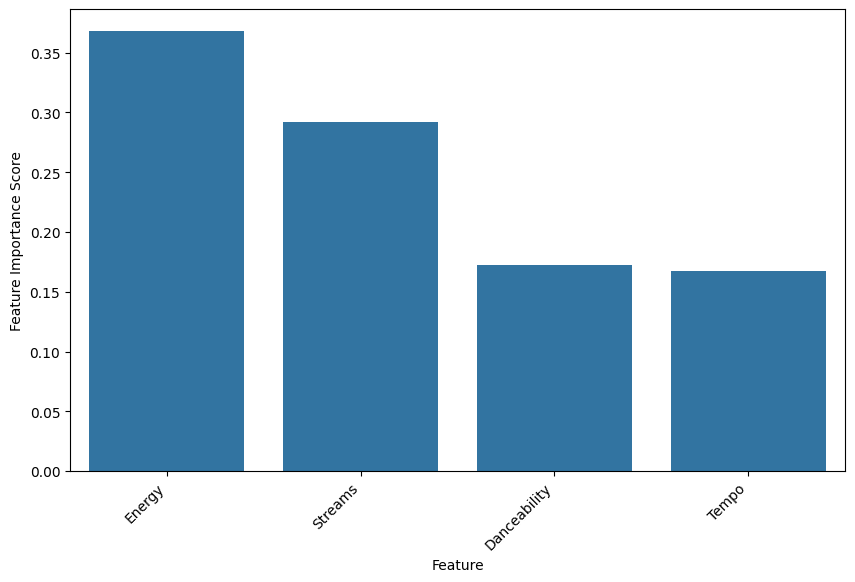

In [29]:
feat_imp = pd.Series(xgbr.feature_importances_, index=X_features.columns).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(x=feat_imp.index, y=feat_imp.values)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Feature')
plt.ylabel('Feature Importance Score') ;

In [30]:
(feat_imp.sort_values( ascending = False )*100).cumsum()

,0
Energy,36.797504
Streams,65.998352
Danceability,83.284058
Tempo,99.999992
